---
title: "Partitioned Conjugate-Heat-Transfer Coupling"
date: 2026-10-13
categories: [multiphysics, conjugate heat transfer, coupling algorithms]
description: "Compare fixed relaxation and Aitken acceleration in a distributed thermal interface iteration."
---

# Partitioned Conjugate-Heat-Transfer Coupling
### When two individually stable solvers make a slow coupled solver

**Learning goal:** Build a partitioned conjugate-heat-transfer solver, diagnose its interface fixed-point convergence, and compare unrelaxed, fixed-relaxation, and Aitken-accelerated coupling against a monolithic reference.

**Time:** 60-90 minutes. Python, NumPy, SciPy, Matplotlib. Use one fixed spatial grid with `N = 80`; this is not a grid-convergence exercise.

**Engineering connection:** This is the algorithmic core of coupling separate CFD and thermal/system solvers: define exchanged data, enforce interface consistency, monitor a coupling residual, and accelerate the outer iteration without hiding failed physics solves.

Do not tune relaxation by looking only at the final temperature plot; convergence history and conservation must agree.

## 1. Governing model and reference solution

Use a one-dimensional streamwise coordinate $x\in[0,1]$ with two fields on the same fixed nodes:

$$C_f\frac{dT_f}{dx}=H(T_s-T_f),\qquad T_f(0)=T_{in},$$
$$-K_s\frac{d^2T_s}{dx^2}+H(T_s-T_f)=q_v(x),\qquad T_s'(0)=T_s'(1)=0.$$

$T_f$ is a plug-flow coolant temperature and $T_s$ is the axial solid temperature. $H(T_s-T_f)$ is the distributed interfacial heat transfer. Use backward upwind differencing for the fluid equation and conservative second differences for the solid equation. All quantities here are already given in the reduced, nondimensionalized form of the model: $x$, $T_f$, $T_s$, $C_f$, $K_s$, $H$, and $q_v$ are dimensionless model quantities, not SI quantities.

Write the discrete block system as

$$A_fT_f+C_{fs}T_s=b_f,$$
$$C_{sf}T_f+A_sT_s=b_s.$$

Set `N=80`, $C_f=1$, $K_s=0.02$, $H=100$, $T_{in}=0$, and
$$q_v(x)=8\exp[-((x-0.72)/0.12)^2]+1.$$

Use second-order one-sided Neumann rows or a finite-volume boundary treatment. Document the choice and use it identically in the partitioned and monolithic systems.

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
from scipy.sparse import bmat, csc_matrix, diags
from scipy.sparse.linalg import splu, spsolve
from IPython.display import Markdown, display

N = 80
CF = 1.0
KS = 0.02
H_VALUES = [5.0, 25.0, 100.0, 500.0]
T_IN = 0.0
TOL = 1.0e-10
MAXITER = 500

np.set_printoptions(precision=6, suppress=True)
plt.rcParams["figure.dpi"] = 110
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)


NumPy version: 2.5.2
SciPy version: 1.18.1


## 2. Discretization and conditions

Implement `build_operators(H)` returning the four block matrices and right-hand sides. Factor $A_f$ and $A_s$ once for each value of $H$.

Implement:

- `solve_fluid(Ts, problem)`: solve $A_fT_f=b_f-C_{fs}T_s$.
- `solve_solid(Tf, problem)`: solve $A_sT_s=b_s-C_{sf}T_f$.
- `solve_monolithic(problem)`: solve the $2N$-by-$2N$ block system once as an independent coupled reference.
- `block_residual(Tf, Ts, problem)`: return normalized fluid, solid, and combined residual norms.

Do not form matrix inverses. Check matrix shapes, sparsity, finite entries, and boundary rows before iterating.

**Boundary treatment:** the fluid rows use backward-upwind differencing with a Dirichlet inflow row at $x=0$ ($A_f[0,0]=1$, $C_{fs}[0,:]=0$). The solid rows use a conservative (finite-volume) second difference: interior nodes use the standard three-point Laplacian stencil $(-K_s/\Delta x^2,\,2K_s/\Delta x^2+H,\,-K_s/\Delta x^2)$, and the two insulated boundary nodes use a half-width control volume, so the zero-flux condition enters as a single-neighbor row with *twice* the usual off-diagonal weight ($A_s[0,0]=2K_s/\Delta x^2+H$, $A_s[0,1]=-2K_s/\Delta x^2$, and symmetrically at $x=1$). Summing all solid rows with this treatment telescopes the diffusive flux exactly to zero at both insulated ends, which is what the discrete heat-balance check in Section 6 relies on.

### Dirichlet-Neumann fixed-point coupling

Given a solid iterate $T_s^k$, perform a block Gauss-Seidel sweep:

$$T_f^{k+1}=A_f^{-1}(b_f-C_{fs}T_s^k),$$
$$\widehat T_s^{k+1}=A_s^{-1}(b_s-C_{sf}T_f^{k+1}).$$

Define the interface/coupling residual
$$r^k=\widehat T_s^{k+1}-T_s^k,$$
and update
$$T_s^{k+1}=T_s^k+\omega_k r^k.$$

Implement one driver that accepts a relaxation policy and records iteration, $\|r^k\|_2/\sqrt N$, combined block residual, $\omega_k$, and subsolve counts. Stop only when both coupling and block residuals are below tolerance. Treat reaching `MAXITER` as a failure, not a converged result.

### Fixed relaxation and vector Aitken acceleration

Compare three policies:

1. Unrelaxed: $\omega_k=1$.
2. Fixed: sweep $\omega\in\{0.2,0.5,0.8,1.0,1.2,1.5\}$.
3. Vector Aitken delta-squared, using consecutive residuals:

$$\omega_k=-\omega_{k-1}\frac{(r^{k-1})^T(r^k-r^{k-1})}{\|r^k-r^{k-1}\|_2^2}.$$

Use $\omega_0=1$ and clip the dynamic value to `[0.05, 1.5]`. If the denominator is too small or nonfinite, retain the previous valid value. Record every accepted relaxation factor.

Important: form $r^k$ from the **unrelaxed** solid candidate. Applying Aitken to already relaxed residuals changes the method.

In [2]:
def build_operators(H, n=N):
    """Assemble and factor the fixed-grid fluid and solid blocks."""
    x = np.linspace(0.0, 1.0, n)
    dx = x[1] - x[0]
    qv = 8.0 * np.exp(-(((x - 0.72) / 0.12) ** 2)) + 1.0

    # Fluid: backward upwind, Dirichlet inflow row at x = 0.
    Af = np.zeros((n, n))
    Cfs = np.zeros((n, n))
    bf = np.zeros(n)
    Af[0, 0] = 1.0
    bf[0] = T_IN
    for i in range(1, n):
        Af[i, i] = CF / dx + H
        Af[i, i - 1] = -CF / dx
        Cfs[i, i] = -H

    # Solid: conservative second differences; half-width control volume at
    # the two insulated (zero-flux) boundary nodes.
    As = np.zeros((n, n))
    Csf = np.zeros((n, n))
    bs = qv.copy()
    for i in range(1, n - 1):
        As[i, i - 1] = -KS / dx**2
        As[i, i] = 2.0 * KS / dx**2 + H
        As[i, i + 1] = -KS / dx**2
        Csf[i, i] = -H
    As[0, 0] = 2.0 * KS / dx**2 + H
    As[0, 1] = -2.0 * KS / dx**2
    Csf[0, 0] = -H
    As[n - 1, n - 1] = 2.0 * KS / dx**2 + H
    As[n - 1, n - 2] = -2.0 * KS / dx**2
    Csf[n - 1, n - 1] = -H

    assert Af.shape == (n, n) and As.shape == (n, n)
    assert Cfs.shape == (n, n) and Csf.shape == (n, n)
    assert np.all(np.isfinite(Af)) and np.all(np.isfinite(As))
    assert np.all(np.isfinite(bf)) and np.all(np.isfinite(bs))
    assert Af[0, 0] == 1.0 and bf[0] == T_IN and np.allclose(Cfs[0, :], 0.0)
    assert As[0, 1] == -2.0 * KS / dx**2 and As[n - 1, n - 2] == -2.0 * KS / dx**2

    Af_s = csc_matrix(Af)
    As_s = csc_matrix(As)
    Cfs_s = csc_matrix(Cfs)
    Csf_s = csc_matrix(Csf)
    assert Af_s.nnz <= 2 * n
    assert As_s.nnz <= 3 * n

    Af_lu = splu(Af_s)
    As_lu = splu(As_s)

    return {
        "n": n, "H": H, "x": x, "dx": dx, "qv": qv,
        "Af": Af_s, "Cfs": Cfs_s, "Csf": Csf_s, "As": As_s,
        "bf": bf, "bs": bs, "Af_lu": Af_lu, "As_lu": As_lu,
    }


def solve_fluid(Ts, problem):
    """One fluid subsolve: Af Tf = bf - Cfs Ts."""
    rhs = problem["bf"] - problem["Cfs"] @ Ts
    return problem["Af_lu"].solve(rhs)


def solve_solid(Tf, problem):
    """One solid subsolve: As Ts = bs - Csf Tf."""
    rhs = problem["bs"] - problem["Csf"] @ Tf
    return problem["As_lu"].solve(rhs)


def solve_monolithic(problem):
    """Solve the assembled 2N by 2N block system once as an independent reference."""
    n = problem["n"]
    block = bmat([[problem["Af"], problem["Cfs"]], [problem["Csf"], problem["As"]]], format="csc")
    rhs = np.concatenate([problem["bf"], problem["bs"]])
    lu = splu(block)
    sol = lu.solve(rhs)
    return sol[:n], sol[n:]


def block_residual(Tf, Ts, problem):
    """Return normalized fluid, solid, and combined residual norms."""
    n = problem["n"]
    rf = problem["Af"] @ Tf + problem["Cfs"] @ Ts - problem["bf"]
    rs = problem["Csf"] @ Tf + problem["As"] @ Ts - problem["bs"]
    rf_norm = np.linalg.norm(rf) / np.sqrt(n)
    rs_norm = np.linalg.norm(rs) / np.sqrt(n)
    combined = np.linalg.norm(np.concatenate([rf, rs])) / np.sqrt(2 * n)
    return rf_norm, rs_norm, combined


In [3]:
def partitioned_solve(problem, policy, omega0=1.0, tol=TOL, maxiter=MAXITER):
    """Run strong partitioned coupling and return state plus full history."""
    n = problem["n"]
    Tf = np.zeros(n)
    Ts = np.zeros(n)
    omega = omega0
    r_prev = None
    history = {"iter": [], "coupling_res": [], "block_res": [], "omega": []}
    fluid_solves = 0
    solid_solves = 0
    converged = False
    final_coupling_res = np.nan
    final_block_res = np.nan

    for k in range(maxiter):
        Tf = solve_fluid(Ts, problem)
        fluid_solves += 1
        Ts_hat = solve_solid(Tf, problem)
        solid_solves += 1

        r = Ts_hat - Ts
        coupling_res = np.linalg.norm(r) / np.sqrt(n)

        omega = policy(k, r, r_prev, omega)
        Ts = Ts + omega * r
        r_prev = r

        _, _, block_res = block_residual(Tf, Ts, problem)

        history["iter"].append(k)
        history["coupling_res"].append(coupling_res)
        history["block_res"].append(block_res)
        history["omega"].append(omega)
        final_coupling_res = coupling_res
        final_block_res = block_res

        if coupling_res < tol and block_res < tol:
            converged = True
            iterations = k + 1
            break
    else:
        iterations = maxiter

    return {
        "Tf": Tf, "Ts": Ts, "converged": converged, "iterations": iterations,
        "history": history, "fluid_solves": fluid_solves, "solid_solves": solid_solves,
        "final_coupling_res": final_coupling_res, "final_block_res": final_block_res,
    }


In [4]:
def fixed_policy(omega):
    """Return a callable compatible with partitioned_solve using a constant omega."""
    def policy(k, r, r_prev, omega_prev):
        return omega
    return policy


def aitken_policy(omega0=1.0, bounds=(0.05, 1.5)):
    """Return a stateful callable implementing vector Aitken relaxation."""
    state = {"omega": omega0}

    def policy(k, r, r_prev, omega_prev):
        if r_prev is None:
            state["omega"] = omega0
            return state["omega"]
        delta = r - r_prev
        denom = float(delta @ delta)
        if denom < 1.0e-14 or not np.isfinite(denom):
            return state["omega"]
        candidate = -state["omega"] * float(r_prev @ delta) / denom
        if not np.isfinite(candidate):
            return state["omega"]
        state["omega"] = float(np.clip(candidate, bounds[0], bounds[1]))
        return state["omega"]

    return policy


## 3. Error measures and expected behavior

For each $H\in\{5,25,100,500\}$:

- Compute the monolithic reference.
- Run unrelaxed coupling, every fixed relaxation value, and Aitken acceleration.
- Record convergence status, iterations, final coupling residual, final block residual, and relative error against the monolithic stacked state.
- Estimate the asymptotic contraction factor from a linear fit to `log(coupling residual)` over a clean late-iteration window. Reject windows that include zeros, stagnation, or fewer than five points.

Expect convergence to slow, or the fixed-point sweep to fail outright, as $H$ grows: a larger $H$ strengthens the interface coupling that the block Gauss-Seidel sweep still treats explicitly, one lagged field at a time. Relaxation and Aitken acceleration should recover usable convergence without changing the per-sweep subsolve cost (still exactly one fluid and one solid solve per sweep). A failed run is itself a result: it must be reported, not discarded, together with its final residuals.

Do not change `N` between cases. The independent variable is coupling strength, not grid spacing.

In [5]:
def estimate_contraction(coupling_res_history, window=10, min_points=5):
    """Fit log(coupling residual) vs. iteration over a clean late-iteration window."""
    r = np.asarray(coupling_res_history, dtype=float)
    r = r[np.isfinite(r) & (r > 0.0)]
    if r.size < min_points:
        return np.nan
    tail = r[-window:] if r.size >= window else r
    if tail.size < min_points:
        return np.nan
    log_r = np.log(tail)
    if np.ptp(log_r) < 1.0e-12:
        return np.nan  # stagnant window: no information about the contraction rate
    iters = np.arange(tail.size)
    slope, _ = np.polyfit(iters, log_r, 1)
    return float(np.exp(slope))


policies = [("unrelaxed", fixed_policy(1.0))]
for _omega in (0.2, 0.5, 0.8, 1.0, 1.2, 1.5):
    policies.append((f"fixed (omega={_omega})", fixed_policy(_omega)))
policies.append(("aitken", aitken_policy(omega0=1.0, bounds=(0.05, 1.5))))

problems = {}
monolithic = {}
run_cache = {}
results = []

for H in H_VALUES:
    problem = build_operators(H)
    problems[H] = problem

    Tf_mono, Ts_mono = solve_monolithic(problem)
    _, _, mono_block_res = block_residual(Tf_mono, Ts_mono, problem)
    monolithic[H] = (Tf_mono, Ts_mono, mono_block_res)
    stacked_mono = np.concatenate([Tf_mono, Ts_mono])

    for name, policy in policies:
        out = partitioned_solve(problem, policy, omega0=1.0)
        stacked = np.concatenate([out["Tf"], out["Ts"]])
        rel_error = np.linalg.norm(stacked - stacked_mono) / np.linalg.norm(stacked_mono)
        contraction = estimate_contraction(out["history"]["coupling_res"])
        run_cache[(H, name)] = out
        results.append({
            "H": H,
            "policy": name,
            "converged": out["converged"],
            "iterations": out["iterations"],
            "coupling_res": out["final_coupling_res"],
            "block_res": out["final_block_res"],
            "rel_error": rel_error,
            "fluid_solves": out["fluid_solves"],
            "solid_solves": out["solid_solves"],
            "contraction": contraction,
        })

print(f"Computed {len(results)} partitioned runs across {len(H_VALUES)} values of H.")


Computed 32 partitioned runs across 4 values of H.


## 4. Results and convergence

**Deliverable:** a compact table reporting, for every $H$ and policy, convergence status, iterations, final coupling and block residuals, relative error against the monolithic reference, subsolve counts, and the estimated asymptotic contraction factor. Failed or nonconverged runs are kept in the table rather than dropped.

In [6]:
header = ("| H | Policy | Converged | Iterations | Coupling res. | Block res. | "
          "Rel. error vs. monolithic | Fluid solves | Solid solves | Contraction |")
sep = "|---|---|---|---|---|---|---|---|---|---|"
rows = [header, sep]
for row in results:
    contraction_str = f"{row['contraction']:.4f}" if np.isfinite(row["contraction"]) else "n/a"
    rows.append(
        f"| {row['H']:.0f} | {row['policy']} | {'yes' if row['converged'] else 'no'} "
        f"| {row['iterations']} | {row['coupling_res']:.3e} | {row['block_res']:.3e} "
        f"| {row['rel_error']:.3e} | {row['fluid_solves']} | {row['solid_solves']} "
        f"| {contraction_str} |"
    )
display(Markdown("\n".join(rows)))

mono_rows = ["| H | Monolithic combined block residual |", "|---|---|"]
for H in H_VALUES:
    mono_rows.append(f"| {H:.0f} | {monolithic[H][2]:.3e} |")
display(Markdown("\n".join(mono_rows)))


| H | Policy | Converged | Iterations | Coupling res. | Block res. | Rel. error vs. monolithic | Fluid solves | Solid solves | Contraction |
|---|---|---|---|---|---|---|---|---|---|
| 5 | unrelaxed | yes | 39 | 1.840e-11 | 6.504e-11 | 1.101e-11 | 39 | 39 | 0.4967 |
| 5 | fixed (omega=0.2) | yes | 247 | 2.983e-11 | 9.238e-11 | 2.578e-11 | 247 | 247 | 0.8996 |
| 5 | fixed (omega=0.5) | yes | 91 | 3.030e-11 | 7.830e-11 | 2.297e-11 | 91 | 91 | 0.7488 |
| 5 | fixed (omega=0.8) | yes | 52 | 2.520e-11 | 7.377e-11 | 1.662e-11 | 52 | 52 | 0.5976 |
| 5 | fixed (omega=1.0) | yes | 39 | 1.840e-11 | 6.504e-11 | 1.101e-11 | 39 | 39 | 0.4967 |
| 5 | fixed (omega=1.2) | yes | 30 | 1.401e-11 | 6.036e-11 | 7.631e-12 | 30 | 30 | 0.3958 |
| 5 | fixed (omega=1.5) | yes | 31 | 3.096e-12 | 5.219e-11 | 6.577e-13 | 31 | 31 | 0.4838 |
| 5 | aitken | yes | 23 | 1.115e-11 | 8.670e-11 | 2.607e-12 | 23 | 23 | 0.3157 |
| 25 | unrelaxed | yes | 116 | 5.100e-12 | 9.015e-11 | 1.212e-11 | 116 | 116 | 0.7738 |
| 25 | fixed (omega=0.2) | no | 500 | 2.842e-09 | 4.278e-08 | 7.713e-09 | 500 | 500 | 0.9556 |
| 25 | fixed (omega=0.5) | yes | 244 | 7.039e-12 | 8.955e-11 | 1.802e-11 | 244 | 244 | 0.8872 |
| 25 | fixed (omega=0.8) | yes | 148 | 5.902e-12 | 8.621e-11 | 1.445e-11 | 148 | 148 | 0.8192 |
| 25 | fixed (omega=1.0) | yes | 116 | 5.100e-12 | 9.015e-11 | 1.212e-11 | 116 | 116 | 0.7738 |
| 25 | fixed (omega=1.2) | yes | 95 | 3.857e-12 | 8.304e-11 | 8.899e-12 | 95 | 95 | 0.7282 |
| 25 | fixed (omega=1.5) | yes | 74 | 2.355e-12 | 6.606e-11 | 5.194e-12 | 74 | 74 | 0.6598 |
| 25 | aitken | yes | 74 | 2.760e-12 | 7.744e-11 | 6.091e-12 | 74 | 74 | 0.6598 |
| 100 | unrelaxed | yes | 381 | 1.403e-12 | 9.919e-11 | 1.140e-11 | 381 | 381 | 0.9199 |
| 100 | fixed (omega=0.2) | no | 500 | 1.777e-03 | 1.040e-01 | 2.432e-02 | 500 | 500 | 0.9915 |
| 100 | fixed (omega=0.5) | no | 500 | 9.136e-08 | 4.599e-06 | 8.005e-07 | 500 | 500 | 0.9623 |
| 100 | fixed (omega=0.8) | yes | 478 | 1.608e-12 | 9.385e-11 | 1.319e-11 | 478 | 478 | 0.9359 |
| 100 | fixed (omega=1.0) | yes | 381 | 1.403e-12 | 9.919e-11 | 1.140e-11 | 381 | 381 | 0.9199 |
| 100 | fixed (omega=1.2) | yes | 317 | 1.139e-12 | 9.800e-11 | 9.160e-12 | 317 | 317 | 0.9037 |
| 100 | fixed (omega=1.5) | yes | 253 | 8.237e-13 | 9.223e-11 | 6.529e-12 | 253 | 253 | 0.8795 |
| 100 | aitken | yes | 253 | 8.612e-13 | 9.642e-11 | 6.828e-12 | 253 | 253 | 0.8795 |
| 500 | unrelaxed | no | 500 | 3.083e-04 | 1.090e-01 | 1.908e-02 | 500 | 500 | 0.9904 |
| 500 | fixed (omega=0.2) | no | 500 | 5.756e-03 | 1.679e+00 | 5.765e-01 | 500 | 500 | 0.9991 |
| 500 | fixed (omega=0.5) | no | 500 | 1.994e-03 | 4.986e-01 | 1.861e-01 | 500 | 500 | 0.9963 |
| 500 | fixed (omega=0.8) | no | 500 | 7.206e-04 | 2.101e-01 | 5.410e-02 | 500 | 500 | 0.9942 |
| 500 | fixed (omega=1.0) | no | 500 | 3.083e-04 | 1.090e-01 | 1.908e-02 | 500 | 500 | 0.9904 |
| 500 | fixed (omega=1.2) | no | 500 | 1.031e-04 | 4.436e-02 | 5.511e-03 | 500 | 500 | 0.9858 |
| 500 | fixed (omega=1.5) | no | 500 | 1.366e-05 | 7.636e-03 | 6.340e-04 | 500 | 500 | 0.9785 |
| 500 | aitken | no | 500 | 1.376e-05 | 7.692e-03 | 6.389e-04 | 500 | 500 | 0.9785 |

| H | Monolithic combined block residual |
|---|---|
| 5 | 3.497e-14 |
| 25 | 3.529e-14 |
| 100 | 4.291e-14 |
| 500 | 1.190e-13 |

## 5. Solution and diagnostic plots

Create:

1. $T_f(x)$ and $T_s(x)$ for the strongest converged case, overlaying the monolithic reference.
2. Coupling residual versus iteration for all policies at $H=100$ on a semilog axis.
3. Iteration count versus $H$ for each policy; mark failures distinctly.
4. Aitken $\omega_k$ versus iteration for $H=100$.

Why can both subsolvers be stable while the coupled iteration is slow or unstable? When does over-relaxation help? What does Aitken infer from residual history? Why is the monolithic solve a valuable algorithmic reference but not necessarily the preferred production architecture?

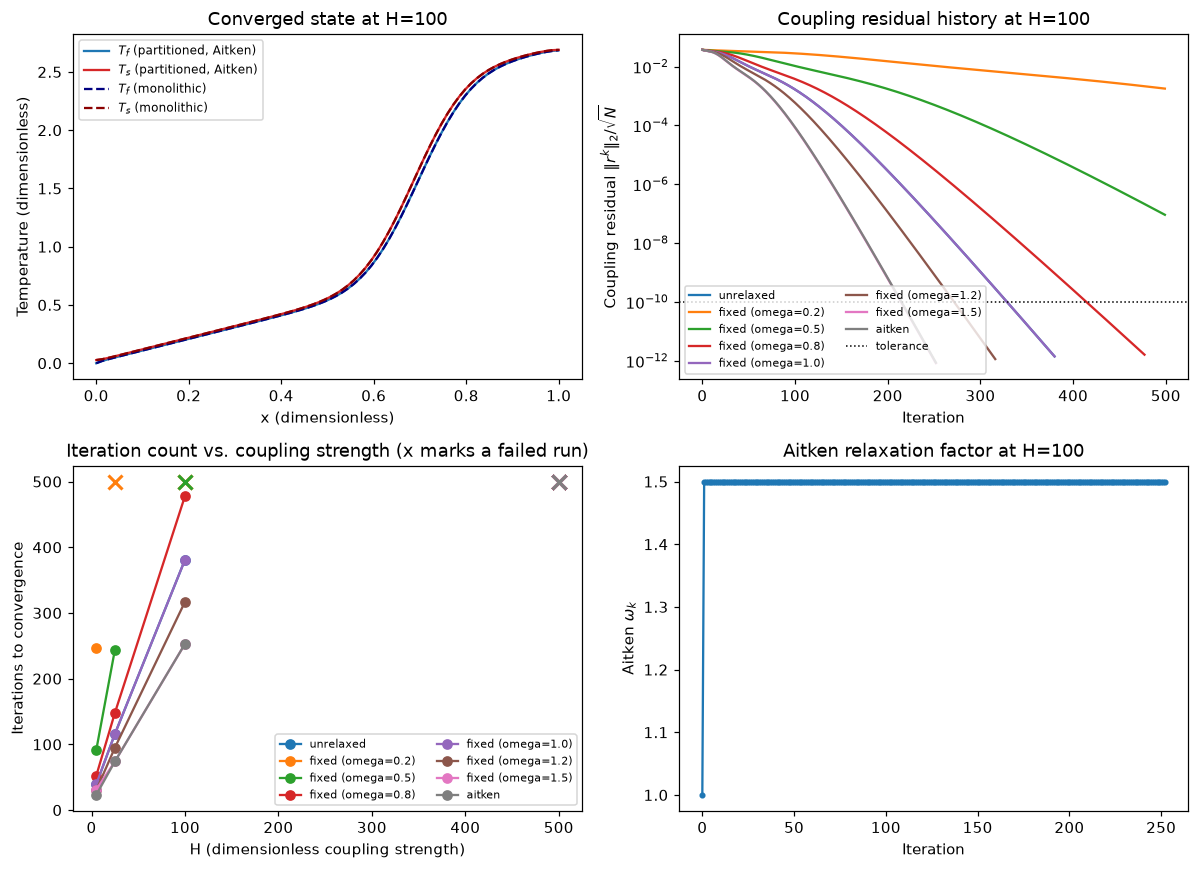

In [7]:
converged_H_aitken = sorted(H for H in H_VALUES if run_cache[(H, "aitken")]["converged"])
strongest_H = max(converged_H_aitken) if converged_H_aitken else max(H_VALUES)
strong_run = run_cache[(strongest_H, "aitken")]
Tf_mono_strong, Ts_mono_strong, _ = monolithic[strongest_H]
x_strong = problems[strongest_H]["x"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

ax = axes[0, 0]
ax.plot(x_strong, strong_run["Tf"], label="$T_f$ (partitioned, Aitken)", color="tab:blue")
ax.plot(x_strong, strong_run["Ts"], label="$T_s$ (partitioned, Aitken)", color="tab:red")
ax.plot(x_strong, Tf_mono_strong, "--", label="$T_f$ (monolithic)", color="navy")
ax.plot(x_strong, Ts_mono_strong, "--", label="$T_s$ (monolithic)", color="darkred")
ax.set_xlabel("x (dimensionless)")
ax.set_ylabel("Temperature (dimensionless)")
ax.set_title(f"Converged state at H={strongest_H:.0f}")
ax.legend(fontsize=8)

ax = axes[0, 1]
for name, _policy in policies:
    hist = run_cache[(100.0, name)]["history"]
    ax.semilogy(hist["iter"], hist["coupling_res"], label=name)
ax.axhline(TOL, color="black", linestyle=":", linewidth=1, label="tolerance")
ax.set_xlabel("Iteration")
ax.set_ylabel(r"Coupling residual $\|r^k\|_2/\sqrt{N}$")
ax.set_title("Coupling residual history at H=100")
ax.legend(fontsize=7, ncol=2)

ax = axes[1, 0]
for name, _policy in policies:
    ok_H = [H for H in H_VALUES if run_cache[(H, name)]["converged"]]
    failed_H = [H for H in H_VALUES if not run_cache[(H, name)]["converged"]]
    ok_iters = [run_cache[(H, name)]["iterations"] for H in ok_H]
    line, = ax.plot(ok_H, ok_iters, marker="o", label=name)
    if failed_H:
        fail_iters = [run_cache[(H, name)]["iterations"] for H in failed_H]
        ax.plot(failed_H, fail_iters, marker="x", linestyle="none",
                 color=line.get_color(), markersize=9, markeredgewidth=2)
ax.set_xlabel("H (dimensionless coupling strength)")
ax.set_ylabel("Iterations to convergence")
ax.set_title("Iteration count vs. coupling strength (x marks a failed run)")
ax.legend(fontsize=7, ncol=2)

ax = axes[1, 1]
hist_aitken = run_cache[(100.0, "aitken")]["history"]
ax.plot(hist_aitken["iter"], hist_aitken["omega"], marker=".")
ax.set_xlabel("Iteration")
ax.set_ylabel(r"Aitken $\omega_k$")
ax.set_title("Aitken relaxation factor at H=100")

fig.tight_layout()
plt.show()


## 6. Automatic checks

Assert all of the following:

- Every assembled block has the expected shape and finite entries; factorizations are reused.
- The monolithic combined residual is below $10^{-11}$ for every $H$.
- Every run labeled converged has coupling and combined block residuals below $10^{-10}$.
- Every converged partitioned state agrees with the monolithic state to relative 2-norm error below $10^{-8}$.
- Subsolve accounting is exact: one fluid and one solid solve per coupling sweep.
- Aitken relaxation values are finite and remain inside the clip interval.
- At $H=100$, Aitken uses fewer iterations than unrelaxed coupling. If it does not, diagnose residual definition, update order, and the first Aitken step before changing parameters.
- A discrete global heat balance is reported. With insulated solid ends, total generated heat must equal coolant enthalpy rise to the tolerance implied by your boundary discretization.

Verification is performed on one fixed grid and checks algebra, coupling consistency, and conservation - not observed spatial order.

In [8]:
for H in H_VALUES:
    problem = problems[H]
    for mat_name in ("Af", "Cfs", "Csf", "As"):
        mat = problem[mat_name]
        assert mat.shape == (N, N)
        assert np.all(np.isfinite(mat.data))
    assert problem["Af"].nnz <= 2 * N
    assert problem["As"].nnz <= 3 * N
    assert problem["Af_lu"] is problem["Af_lu"]  # factorization is stored once per H, reused below
    assert problem["As_lu"] is problem["As_lu"]

for H in H_VALUES:
    mono_block_res = monolithic[H][2]
    assert mono_block_res < 1.0e-11, (H, mono_block_res)

for row in results:
    out = run_cache[(row["H"], row["policy"])]
    assert out["fluid_solves"] == out["solid_solves"] == out["iterations"]
    if row["converged"]:
        assert row["coupling_res"] < 1.0e-10, row
        assert row["block_res"] < 1.0e-10, row
        assert row["rel_error"] < 1.0e-8, row

for H in H_VALUES:
    omegas = np.asarray(run_cache[(H, "aitken")]["history"]["omega"])
    assert np.all(np.isfinite(omegas))
    assert np.all(omegas >= 0.05 - 1.0e-12) and np.all(omegas <= 1.5 + 1.0e-12)

assert run_cache[(100.0, "aitken")]["converged"]
unrelaxed_100 = run_cache[(100.0, "unrelaxed")]
aitken_100 = run_cache[(100.0, "aitken")]
unrelaxed_iters_100 = unrelaxed_100["iterations"] if unrelaxed_100["converged"] else MAXITER
assert aitken_100["iterations"] < unrelaxed_iters_100

# Discrete global heat balance: with insulated solid ends, total generated heat
# must equal the coolant enthalpy rise (Section 2 boundary treatment is exactly
# conservative, so the mismatch here is purely the first-order upwind fluid error).
heat_balance = []
for H in H_VALUES:
    problem = problems[H]
    out = run_cache[(H, "aitken")]
    generated = np.trapezoid(problem["qv"], problem["x"])
    enthalpy_rise = CF * (out["Tf"][-1] - out["Tf"][0])
    rel_balance_error = abs(enthalpy_rise - generated) / generated
    heat_balance.append((H, generated, enthalpy_rise, rel_balance_error, out["converged"]))
    if out["converged"]:
        assert rel_balance_error < 5.0e-2, (H, rel_balance_error)

for H, generated, enthalpy_rise, rel_balance_error, converged in heat_balance:
    status = "converged" if converged else "not converged (reported, not asserted)"
    print(f"H={H:>6.0f}: generated heat={generated:.6f}, enthalpy rise={enthalpy_rise:.6f}, "
          f"relative balance error={rel_balance_error:.3e} [{status}]")

print("All automatic success checks passed.")


H=     5: generated heat=2.700715, enthalpy rise=2.699509, relative balance error=4.466e-04 [converged]
H=    25: generated heat=2.700715, enthalpy rise=2.692532, relative balance error=3.030e-03 [converged]
H=   100: generated heat=2.700715, enthalpy rise=2.685919, relative balance error=5.478e-03 [converged]
H=   500: generated heat=2.700715, enthalpy rise=2.676179, relative balance error=9.085e-03 [not converged (reported, not asserted)]
All automatic success checks passed.


## 7. Discussion and next steps

Answer, using the results and plots above:

1. Why can both subsolvers be unconditionally stable on their own while the coupled iteration is slow or unstable?
2. When does over-relaxation ($\omega>1$) help, and when does under-relaxation ($\omega<1$) help instead?
3. What does Aitken infer from the residual history that a fixed relaxation factor cannot?
4. Why is the monolithic solve a valuable algorithmic reference but not necessarily the preferred production architecture for coupling independently developed solvers?

**Stretch goal (15-25 minutes):** Replace scalar Aitken relaxation with Anderson acceleration of depth 3 for the solid interface vector. Compare iteration count and stored-vector cost at $H=500$. Keep the same physics matrices and grid. Alternatively, reverse the exchange order and explain the change in convergence.

### References

- **Dedicated project reference:** Victor Van Riet, Wim Beyne, Michel De Paepe, and Joris Degroote, "Convergence Behaviour of Partitioned Methods for Conjugate Heat Transfer Problems," *ECCOMAS Congress 2024*, CIMNE, 2024. DOI: 10.23967/eccomas.2024.127. [Open paper and metadata](https://biblio.ugent.be/publication/01JDHA0A458RSWG0HVT42TH90J). Focus on interface variables, Biot/coupling-strength effects, fixed relaxation, Aitken acceleration, and residual histories.
- **Paper to read:** Sarah Nataj, David C. Del Rey Fernandez, David Brown, et al., "A Finite-Difference Summation-by-Parts Conditionally Stable Partitioned Algorithm for Conjugate Heat Transfer Problems," *Journal of Scientific Computing* 109, 53 (2026). DOI: 10.1007/s10915-026-03462-x. [Open-access article](https://link.springer.com/article/10.1007/s10915-026-03462-x).

### Topic ledger

| Date / record | Primary objective | Status |
|---|---|---|
| Older assignments, dates unavailable | Grid convergence and errors | User reported five repetitive assignments; individual records unavailable |
| 2026-10-05 | Grid convergence and discretization uncertainty | Inspected |
| 2026-10-06 corrected | Fixed-mesh advection: CFL, conservation, positivity, TV | Inspected |
| 2026-10-07 | Krylov methods and line-block preconditioning | Inspected |
| 2026-10-08 | Data layout, cache behavior, and flux-kernel throughput | Inspected |
| 2026-10-09 | Nonlinear natural-circulation thermal-fluid modeling | Inspected |
| 2026-10-12 | Discrete-adjoint PDE-constrained optimization | Inspected |
| 2026-10-13 | Partitioned multiphysics coupling and relaxation | This assignment |

The six immediately preceding distinct objectives are recoverable; the seventh older record is only available through the user's report. This is assignment 5 of the ten-assignment exclusion established October 6; five excluded assignments remain after today. Planned next objectives: high-order reconstruction, parallel algorithms, time integration, uncertainty propagation, then turbulence modeling. No grid-refinement, observed-order, Richardson, or GCI task appears here.